# Unemployment Analysis with Python

### Oasis Infobyte — Data Science Internship

**Intern:** Vansh Gandhi  
**Track:** Data Science  
**Project:** Task 2 — Unemployment Analysis with Python

---

## 1. Project Overview

Unemployment is an important economic indicator that helps us understand labour-market conditions. This project explores unemployment trends across different regions of India using Python and data analysis techniques.

The analysis focuses on regional differences, changes over time, relationships between employment indicators, and a comparison of unemployment rates before and after the COVID-19 period.

## 2. Project Objectives

- Examine the structure and quality of the unemployment dataset.
- Analyse average unemployment rates across regions.
- Explore monthly unemployment trends.
- Compare unemployment trends across at least three major regions.
- Identify the ten regions with the highest average unemployment rates.
- Study correlations between unemployment rate, estimated employment, and labour force participation rate.
- Compare average unemployment rates before and after the COVID-19 period.
- Present findings through clear visualisations and evidence-based observations.

## 3. Tools and Libraries

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## 4. Dataset

The primary dataset used in this project is `Unemployment in India.csv`.

The dataset contains regional unemployment information, including dates, unemployment rates, estimated employment, labour force participation rates, and area classifications.

The dataset will be inspected before cleaning or analysis. Any data-quality issues and preprocessing decisions will be documented in the relevant sections.

## 5. Analysis Workflow

1. Import libraries and configure visualisations.
2. Load and inspect the dataset.
3. Clean and prepare the data.
4. Perform exploratory data analysis.
5. Analyse regional and monthly unemployment trends.
6. Visualise trends across major regions.
7. Identify the ten regions with the highest average unemployment rates.
8. Analyse correlations between employment indicators.
9. Compare pre-COVID and post-COVID unemployment rates.
10. Summarise findings and conclusions.

In [1]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns when inspecting DataFrames
pd.set_option("display.max_columns", None)

# Improve the default appearance of visualisations
sns.set_theme(style="whitegrid", palette="deep")

# Configure plot dimensions and resolution
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 100

print("All libraries imported successfully.")

All libraries imported successfully.


## 6. Loading the Dataset

The primary unemployment dataset is loaded using Pandas.

The initial inspection will help us understand the records, column names, and general structure before performing data cleaning or transformations.

In [2]:
# ==========================================
# 2. LOAD THE DATASET
# ==========================================

from pathlib import Path

# Locate the Task 2 dataset folder
task2_dir = (
    Path.cwd().parent
    / "DataScience-Task2-UnemploymentAnalysis"
)

# Define the primary dataset path
file_path = task2_dir / "data" / "raw" / "Unemployment in India.csv"

# Verify that the dataset exists
if not file_path.exists():
    raise FileNotFoundError(f"Dataset not found at: {file_path}")

# Load the dataset
df = pd.read_csv(file_path)

# Display the first five records
print("Dataset loaded successfully!")
display(df.head())

Dataset loaded successfully!


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


## 7. Initial Dataset Inspection

Before cleaning the dataset, we examine its dimensions, column names, data types, missing values, and descriptive statistics.

This initial inspection helps identify potential data-quality issues and determines which preprocessing steps are necessary.

In [3]:
# ==========================================
# 3. INITIAL DATASET INSPECTION
# ==========================================

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDataset Information:")
df.info()

# Missing values
print("\nMissing Values:")
display(df.isnull().sum().to_frame(name="Missing Values"))

# Descriptive statistics
print("\nDescriptive Statistics:")
display(df.describe(include="all").T)

Dataset Shape: (768, 7)

Column Names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    str    
 1    Date                                     740 non-null    str    
 2    Frequency                                740 non-null    str    
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    str    
dtypes: float64(3), str(4)
memory usage: 42.1 KB

Missing Valu

,Missing Values
Region,28
Date,28
Frequency,28
Estimated Unemployment Rate (%),28
Estimated Employed,28
Estimated Labour Participation Rate (%),28
Area,28



Descriptive Statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Region,740,28,Andhra Pradesh,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,740,14,31-10-2019,55,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Frequency,740,2,Monthly,381,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Estimated Unemployment Rate (%),740.0,NaN,NaN,NaN,11.787946,10.721298,0.0,4.6575,8.35,15.8875,76.74
Estimated Employed,740.0,NaN,NaN,NaN,7204460.025676,8087988.429458,49420.0,1190404.5,4744178.5,11275489.5,45777509.0
Estimated Labour Participation Rate (%),740.0,NaN,NaN,NaN,42.630122,8.111094,13.33,38.0625,41.16,45.505,72.57
Area,740,2,Urban,381,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 8. Data Quality Assessment

The initial inspection identified missing values in the dataset and leading or trailing whitespace in several column names.

Before applying cleaning operations, we investigate whether the missing values belong to completely empty rows or partially populated records.

We also examine duplicate records, category consistency, and date formatting to determine the appropriate preprocessing steps.

In [4]:
# ==========================================
# 4. DATA QUALITY INVESTIGATION
# ==========================================

# 1. Check completely empty rows
empty_rows = df.isna().all(axis=1).sum()

# 2. Check rows containing at least one missing value
rows_with_missing = df.isna().any(axis=1).sum()

# 3. Check rows containing partial missing values
partial_missing_rows = (
    df.isna().any(axis=1) & ~df.isna().all(axis=1)
).sum()

# 4. Check duplicate records
duplicate_rows = df.duplicated().sum()

print("Completely Empty Rows:", empty_rows)
print("Rows With Any Missing Values:", rows_with_missing)
print("Partially Missing Rows:", partial_missing_rows)
print("Duplicate Rows:", duplicate_rows)

# 5. Inspect unique categories
print("\nFrequency Categories:")
print(df[" Frequency"].value_counts(dropna=False))

print("\nArea Categories:")
print(df["Area"].value_counts(dropna=False))

# 6. Inspect date values
print("\nSample Date Values:")
print(df[" Date"].dropna().unique()[:10])

# 7. Inspect missing-value rows
print("\nSample Rows Containing Missing Values:")
display(df[df.isna().any(axis=1)].head(10))

Completely Empty Rows: 28
Rows With Any Missing Values: 28
Partially Missing Rows: 0
Duplicate Rows: 27

Frequency Categories:
 Frequency
Monthly     381
 Monthly    359
NaN          28
Name: count, dtype: int64

Area Categories:
Area
Urban    381
Rural    359
NaN       28
Name: count, dtype: int64

Sample Date Values:
<StringArray>
[' 31-05-2019', ' 30-06-2019', ' 31-07-2019', ' 31-08-2019', ' 30-09-2019',
 ' 31-10-2019', ' 30-11-2019', ' 31-12-2019', ' 31-01-2020', ' 29-02-2020']
Length: 10, dtype: str

Sample Rows Containing Missing Values:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
359,NaN,NaN,NaN,NaN,NaN,NaN,NaN
360,NaN,NaN,NaN,NaN,NaN,NaN,NaN
361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
363,NaN,NaN,NaN,NaN,NaN,NaN,NaN
364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
365,NaN,NaN,NaN,NaN,NaN,NaN,NaN
366,NaN,NaN,NaN,NaN,NaN,NaN,NaN
367,NaN,NaN,NaN,NaN,NaN,NaN,NaN
368,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 9. Data Cleaning and Preprocessing

The dataset requires a few preprocessing operations before analysis.

The following steps will be performed:

1. Create a copy of the original dataset to preserve raw data.
2. Remove completely empty rows.
3. Remove leading and trailing whitespace from column names and text values.
4. Convert the Date column into a proper datetime format.
5. Identify and remove duplicate observations after standardising text values.
6. Verify missing values and data types after cleaning.

The cleaning process will be documented using row counts and data-quality checks.

In [5]:
# ==========================================
# 5. DATA CLEANING AND PREPROCESSING
# ==========================================

# Preserve the original dataset
df_clean = df.copy()

# Record the original number of rows
original_rows = len(df_clean)

# Step 1: Remove completely empty rows
df_clean = df_clean.dropna(how="all").copy()

# Step 2: Standardise column names
df_clean.columns = df_clean.columns.str.strip()

# Step 3: Remove leading and trailing whitespace
# from all string values
for column in df_clean.select_dtypes(include=["object", "str"]).columns:
    df_clean[column] = df_clean[column].map(
        lambda value: value.strip() if isinstance(value, str) else value
    )

# Step 4: Convert Date into datetime format
df_clean["Date"] = pd.to_datetime(
    df_clean["Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Count dates that could not be converted
invalid_dates = df_clean["Date"].isna().sum()

# Step 5: Remove duplicate observations
duplicates_removed = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates().copy()

# Step 6: Display cleaning summary
print("DATA CLEANING SUMMARY")
print("-" * 40)
print("Original rows:", original_rows)
print("Completely empty rows removed:", original_rows - df.dropna(how="all").shape[0])
print("Duplicate rows removed:", duplicates_removed)
print("Invalid dates:", invalid_dates)
print("Final rows:", len(df_clean))
print("Final columns:", len(df_clean.columns))

# Step 7: Verify cleaned dataset
print("\nRemaining Missing Values:")
display(df_clean.isnull().sum().to_frame(name="Missing Values"))

print("\nUpdated Data Types:")
display(df_clean.dtypes.to_frame(name="Data Type"))

print("\nCleaned Dataset Preview:")
display(df_clean.head())

DATA CLEANING SUMMARY
----------------------------------------
Original rows: 768
Completely empty rows removed: 28
Duplicate rows removed: 0
Invalid dates: 0
Final rows: 740
Final columns: 7

Remaining Missing Values:


,Missing Values
Region,0
Date,0
Frequency,0
Estimated Unemployment Rate (%),0
Estimated Employed,0
Estimated Labour Participation Rate (%),0
Area,0



Updated Data Types:


,Data Type
Region,str
Date,datetime64[us]
Frequency,str
Estimated Unemployment Rate (%),float64
Estimated Employed,float64
Estimated Labour Participation Rate (%),float64
Area,str



Cleaned Dataset Preview:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


## 10. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps identify patterns, distributions, and variations within the unemployment dataset.

In this section, we examine:
- Overall statistical characteristics of unemployment.
- Average unemployment rates across regions.
- Distribution of unemployment rates.
- Differences between Rural and Urban areas.
- Changes in unemployment across different months.

In [6]:
# ==========================================
# 7. BASIC EXPLORATORY DATA ANALYSIS
# ==========================================

# Overall statistical summary
print("Overall Statistical Summary:")
display(df_clean.describe().T)

# Number of unique regions
print("\nNumber of Unique Regions:")
print(df_clean["Region"].nunique())

# List of regions
print("\nRegions:")
print(sorted(df_clean["Region"].unique()))

# Observation counts by area
print("\nObservations by Area:")
display(df_clean["Area"].value_counts().to_frame("Count"))

# Observation counts by frequency
print("\nObservations by Frequency:")
display(df_clean["Frequency"].value_counts().to_frame("Count"))

# Overall average unemployment rate
print("\nOverall Average Unemployment Rate:")
print(round(df_clean["Estimated Unemployment Rate (%)"].mean(), 2), "%")

Overall Statistical Summary:


,count,mean,min,25%,50%,75%,max,std
Date,740,2019-12-12 18:36:58.378378,2019-05-31 00:00:00,2019-08-31 00:00:00,2019-11-30 00:00:00,2020-03-31 00:00:00,2020-06-30 00:00:00,NaN
Estimated Unemployment Rate (%),740.0,11.787946,0.0,4.6575,8.35,15.8875,76.74,10.721298
Estimated Employed,740.0,7204460.025676,49420.0,1190404.5,4744178.5,11275489.5,45777509.0,8087988.429458
Estimated Labour Participation Rate (%),740.0,42.630122,13.33,38.0625,41.16,45.505,72.57,8.111094



Number of Unique Regions:
28

Regions:
['Andhra Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu & Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'Meghalaya', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']

Observations by Area:


,Count
Area,
Urban,381
Rural,359



Observations by Frequency:


,Count
Frequency,
Monthly,740



Overall Average Unemployment Rate:
11.79 %


## 11. Region-wise Average Unemployment Analysis

This section calculates the average unemployment rate for each region.

The dataset contains both Rural and Urban observations. We will calculate the regional average across both area categories, giving each recorded observation equal weight.

The resulting averages will help identify regional differences in unemployment rates.

Average Unemployment Rate by Region:


,Average Unemployment Rate (%)
Region,
Tripura,28.35
Haryana,26.28
Jharkhand,20.58
Bihar,18.92
Himachal Pradesh,18.54
Delhi,16.50
Jammu & Kashmir,16.19
Chandigarh,15.99
Rajasthan,14.06


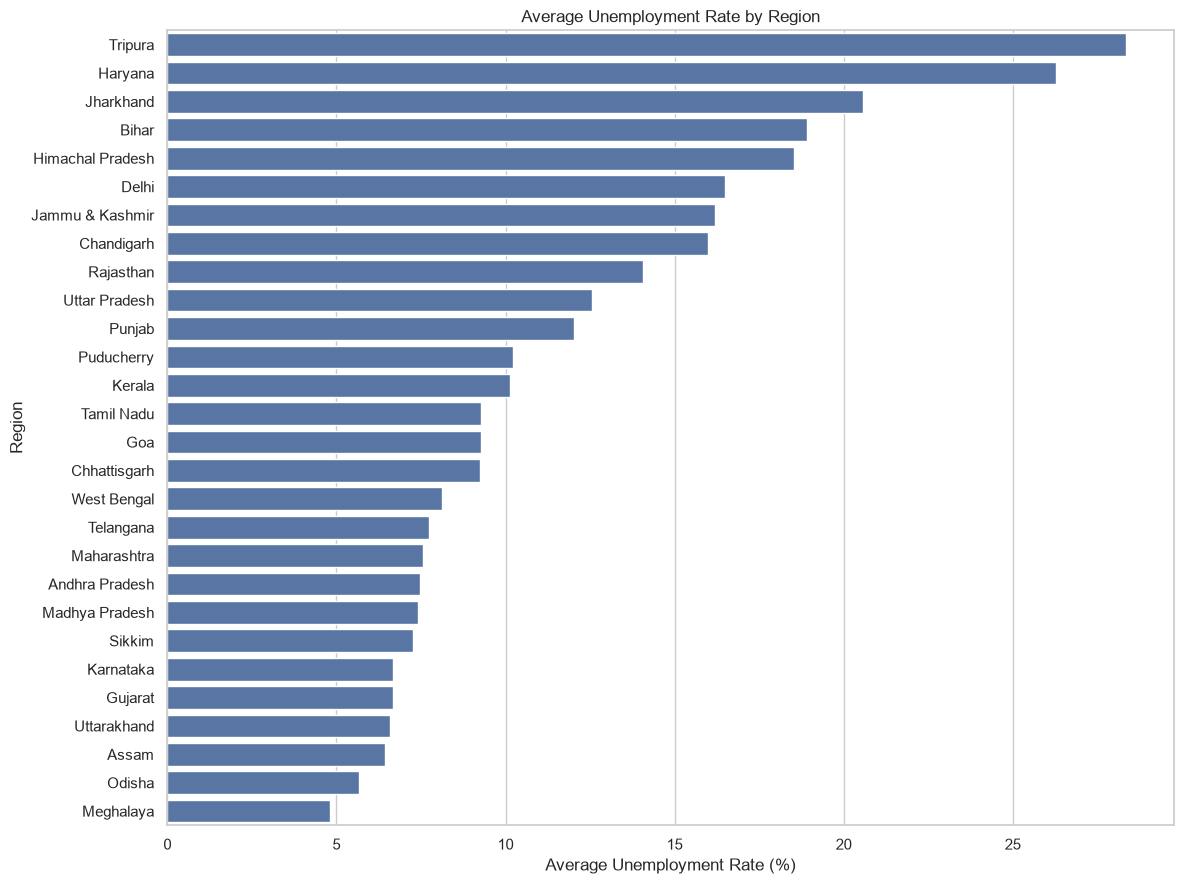

In [7]:
# ==========================================
# 8. REGION-WISE AVERAGE UNEMPLOYMENT
# ==========================================

# Calculate average unemployment rate by region
regional_avg = (
    df_clean.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
)

# Display regional averages
print("Average Unemployment Rate by Region:")
display(
    regional_avg.to_frame(
        name="Average Unemployment Rate (%)"
    ).round(2)
)

# Create a horizontal bar chart
plt.figure(figsize=(12, 9))

sns.barplot(
    x=regional_avg.values,
    y=regional_avg.index
)

plt.title("Average Unemployment Rate by Region")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

### Regional Unemployment — Key Observations

- Tripura recorded the highest average unemployment rate among the regions in the dataset.
- Haryana and Jharkhand also showed relatively high average unemployment rates.
- Meghalaya recorded the lowest average unemployment rate.
- There are noticeable differences in average unemployment rates across regions.
- These averages combine Rural and Urban observations over the available period, so they do not represent the unemployment rate of a region at a single point in time.

The results highlight regional variation in unemployment and motivate further investigation into how unemployment changed over time.

## 12. Month-wise Unemployment Trends

This section examines changes in unemployment rates over the available observation period.

The monthly average unemployment rate will be calculated across all recorded regions and area categories. A line chart will be used to visualise the overall trend.

This provides an overview of how unemployment changed between May 2019 and June 2020.

Monthly Average Unemployment Rate:


,Average Unemployment Rate (%)
Date,
2019-05-31,8.87
2019-06-30,9.30
2019-07-31,9.03
2019-08-31,9.64
2019-09-30,9.05
2019-10-31,9.90
2019-11-30,9.87
2019-12-31,9.50
2020-01-31,9.95


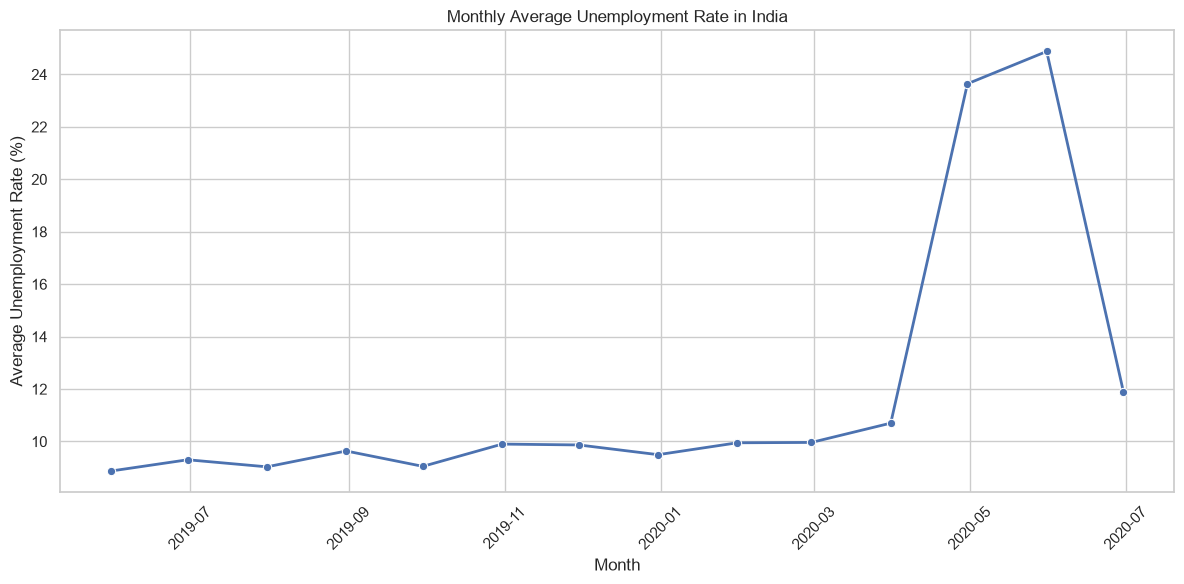

In [8]:
# ==========================================
# 9. MONTH-WISE UNEMPLOYMENT TRENDS
# ==========================================

# Group observations by date and calculate
# the average unemployment rate
monthly_avg = (
    df_clean.groupby("Date")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_index()
)

# Display monthly averages
print("Monthly Average Unemployment Rate:")
display(
    monthly_avg.to_frame(
        name="Average Unemployment Rate (%)"
    ).round(2)
)

# Create a time-series line chart
plt.figure(figsize=(12, 6))

sns.lineplot(
    x=monthly_avg.index,
    y=monthly_avg.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Average Unemployment Rate in India")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Monthly Unemployment Trends — Key Observations

- From May 2019 to March 2020, the average unemployment rate remained relatively stable, generally between 9% and 11%.
- A sharp increase occurred in April 2020.
- The highest monthly average was observed in May 2020, at approximately 24.9%.
- The average unemployment rate declined considerably in June 2020.
- The sudden increase coincides with the COVID-19 period and indicates a major change in labour-market conditions during this time.

These observations describe the pattern in the dataset and do not independently establish the causes of the changes.

## 13. Unemployment Trends Across Major Regions

This section compares unemployment rates over time across three regions: Tripura, Haryana, and Jharkhand.

The dataset contains Rural and Urban observations for each region. To compare regional trends consistently, we calculate the average unemployment rate for each region and date across both area categories.

A multi-line time-series chart will help identify similarities and differences in their unemployment patterns.

Monthly Unemployment Rates for Selected Regions:


Region,Haryana,Jharkhand,Tripura
Date,,,
2019-05-31,19.60,12.17,31.97
2019-06-30,21.75,14.49,26.12
2019-07-31,20.84,12.82,24.14
2019-08-31,27.56,16.16,29.47
2019-09-30,21.60,14.14,31.90
2019-10-31,22.60,12.81,27.10
2019-11-30,21.82,12.70,26.20
2019-12-31,26.60,18.58,30.00
2020-01-31,21.72,14.56,33.14


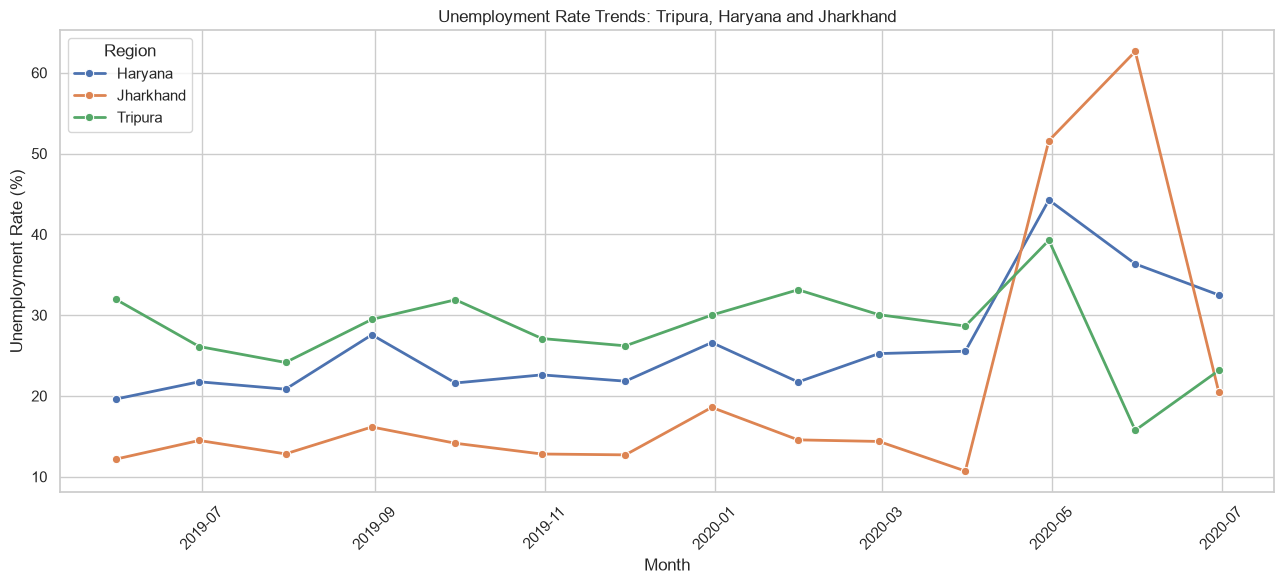

In [9]:
# ==========================================
# 10. TIME-SERIES COMPARISON OF THREE REGIONS
# ==========================================

# Select the three regions with the highest
# average unemployment rates
selected_regions = ["Tripura", "Haryana", "Jharkhand"]

# Filter the dataset
region_trends = df_clean[
    df_clean["Region"].isin(selected_regions)
].copy()

# Calculate average unemployment by region and date
region_monthly = (
    region_trends.groupby(["Date", "Region"])[
        "Estimated Unemployment Rate (%)"
    ]
    .mean()
    .reset_index()
)

# Display the monthly values
print("Monthly Unemployment Rates for Selected Regions:")
display(
    region_monthly.pivot(
        index="Date",
        columns="Region",
        values="Estimated Unemployment Rate (%)"
    ).round(2)
)

# Plot the three regional trends
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=region_monthly,
    x="Date",
    y="Estimated Unemployment Rate (%)",
    hue="Region",
    marker="o",
    linewidth=2
)

plt.title("Unemployment Rate Trends: Tripura, Haryana and Jharkhand")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.legend(title="Region")
plt.tight_layout()
plt.show()

### Regional Time-Series Analysis — Key Observations

- Tripura maintained comparatively high unemployment rates throughout much of the observation period.
- Haryana experienced a substantial increase in unemployment during May 2020, followed by a decline.
- Jharkhand recorded the most pronounced increase, reaching approximately 62.6% in June 2020.
- All three regions experienced considerable unemployment fluctuations during the COVID-19 period.
- The magnitude and timing of unemployment changes differed across the three regions.

These findings demonstrate that unemployment trends varied considerably across regions rather than following an identical pattern.

## 14. Top 10 Regions with the Highest Average Unemployment Rates

This section identifies the ten regions with the highest average unemployment rates during the observation period.

The regional averages are calculated using both Rural and Urban observations. The results are sorted in descending order and displayed using a bar chart to make regional comparisons easier.

Top 10 Regions with Highest Average Unemployment:


,Average Unemployment Rate (%)
Region,
Tripura,28.35
Haryana,26.28
Jharkhand,20.58
Bihar,18.92
Himachal Pradesh,18.54
Delhi,16.50
Jammu & Kashmir,16.19
Chandigarh,15.99
Rajasthan,14.06


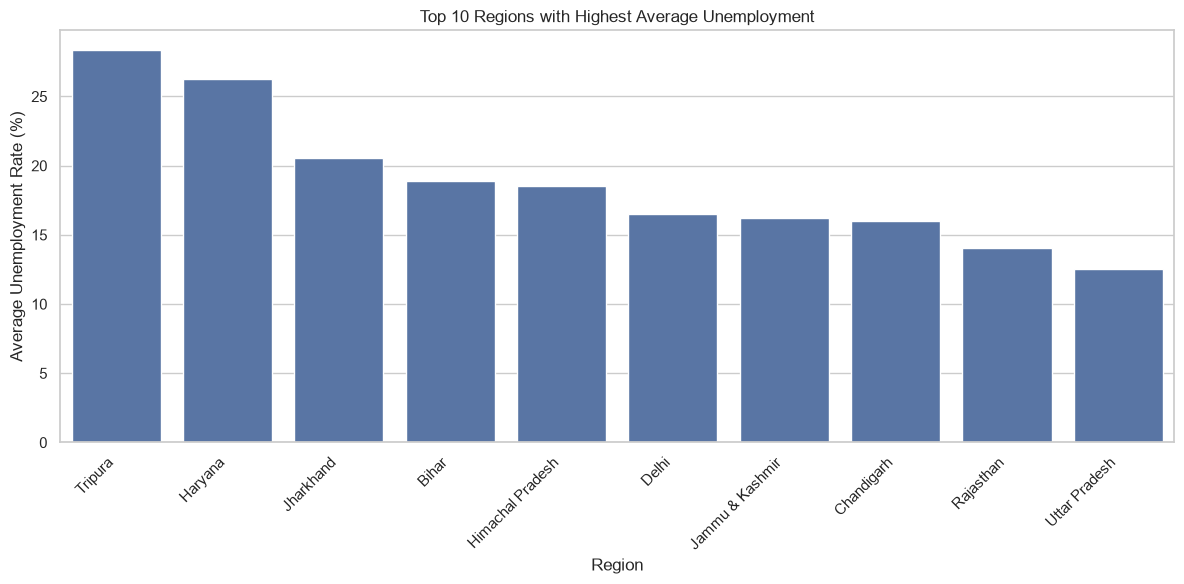

In [10]:
# ==========================================
# 11. TOP 10 REGIONS BY AVERAGE UNEMPLOYMENT
# ==========================================

# Calculate average unemployment rate by region
top_10_regions = (
    df_clean.groupby("Region")["Estimated Unemployment Rate (%)"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

# Display the top 10 regions
print("Top 10 Regions with Highest Average Unemployment:")
display(
    top_10_regions.to_frame(
        name="Average Unemployment Rate (%)"
    ).round(2)
)

# Create bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_regions.index,
    y=top_10_regions.values
)

plt.title("Top 10 Regions with Highest Average Unemployment")
plt.xlabel("Region")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Top 10 Regions — Key Observations

- Tripura recorded the highest average unemployment rate, followed by Haryana.
- Jharkhand ranked third among the regions.
- Bihar and Himachal Pradesh also recorded relatively high average unemployment rates.
- Uttar Pradesh ranked tenth among the top ten regions.
- The difference between the highest and tenth-highest regional averages is substantial.

These results highlight the variation in average unemployment rates across Indian regions during the dataset's observation period.

## 15. Correlation Analysis

Correlation analysis helps examine the strength and direction of linear relationships between numerical variables.

This section investigates the relationships between unemployment rate, estimated employment, and labour force participation rate using a Pearson correlation matrix.

A heatmap will display the correlation coefficients, where values closer to +1 indicate positive relationships, values closer to -1 indicate negative relationships, and values near zero indicate weak linear relationships.

Correlation does not establish causation.

Correlation Matrix:


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.000,-0.223,0.003
Estimated Employed,-0.223,1.000,0.011
Estimated Labour Participation Rate (%),0.003,0.011,1.000


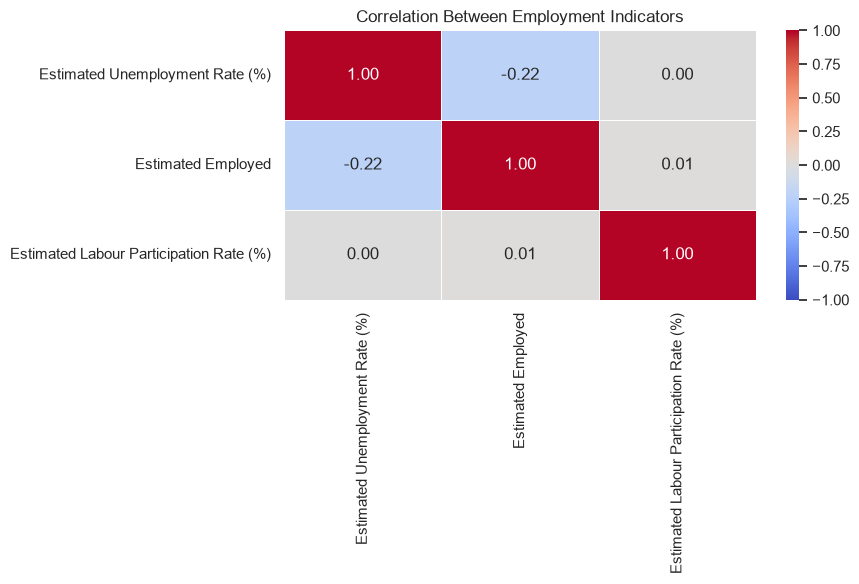

In [11]:
# ==========================================
# 12. CORRELATION ANALYSIS
# ==========================================

# Select the three required numerical variables
correlation_columns = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]

# Calculate Pearson correlation matrix
correlation_matrix = df_clean[correlation_columns].corr(method="pearson")

# Display correlation values
print("Correlation Matrix:")
display(correlation_matrix.round(3))

# Create correlation heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Employment Indicators")
plt.tight_layout()
plt.show()

### Correlation Analysis — Key Observations

- The correlation between unemployment rate and estimated employment is approximately -0.22, indicating a weak negative linear relationship.
- The correlation between unemployment rate and labour force participation rate is approximately 0.00, suggesting almost no linear relationship in this dataset.
- The correlation between estimated employment and labour force participation rate is approximately 0.01, indicating a negligible linear relationship.
- None of the three variable pairs demonstrates a strong linear correlation.

These results describe the linear associations in the available observations. They do not establish causal relationships, and the correlation between estimated employment and unemployment may also be influenced by differences in regional population sizes.

## 16. Pre-COVID vs Post-COVID Unemployment Comparison

This section compares unemployment rates before and after the beginning of India's nationwide COVID-19 lockdown.

For this analysis, 25 March 2020 is used as the comparison boundary.

- Pre-COVID period: observations dated before 25 March 2020.
- Post-COVID period: observations dated on or after 25 March 2020.

The mean unemployment rate for each period will be calculated and compared using a bar chart.

This is a descriptive comparison of the available dataset and does not independently establish that COVID-19 caused the observed changes.

PRE-COVID VS POST-COVID COMPARISON
---------------------------------------------
Pre-COVID observations: 536
Post-COVID observations: 204
Pre-COVID average unemployment: 9.51%
Post-COVID average unemployment: 17.77%
Change in unemployment rate: 8.26 percentage points


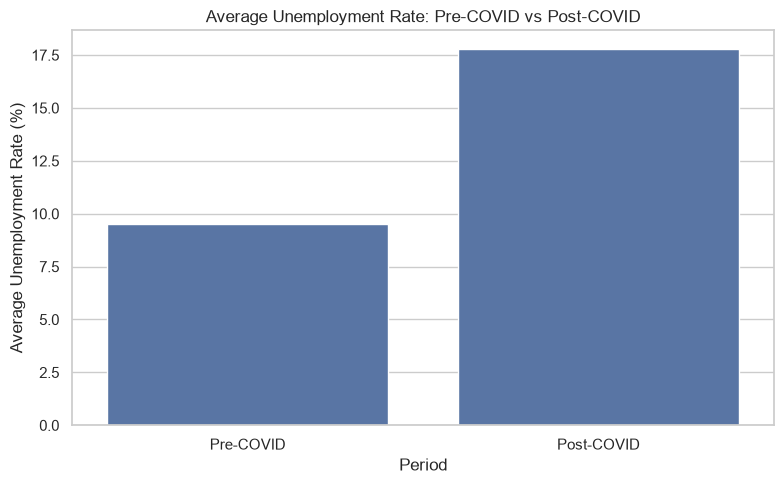

In [12]:
# ==========================================
# 13. PRE-COVID VS POST-COVID COMPARISON
# ==========================================

# Define the COVID-19 comparison boundary
covid_cutoff = pd.Timestamp("2020-03-25")

# Separate observations into two periods
pre_covid = df_clean[df_clean["Date"] < covid_cutoff].copy()

post_covid = df_clean[df_clean["Date"] >= covid_cutoff].copy()

# Calculate average unemployment rates
pre_covid_avg = pre_covid["Estimated Unemployment Rate (%)"].mean()
post_covid_avg = post_covid["Estimated Unemployment Rate (%)"].mean()

# Calculate absolute and percentage-point change
absolute_change = post_covid_avg - pre_covid_avg

print("PRE-COVID VS POST-COVID COMPARISON")
print("-" * 45)
print(f"Pre-COVID observations: {len(pre_covid)}")
print(f"Post-COVID observations: {len(post_covid)}")
print(f"Pre-COVID average unemployment: {pre_covid_avg:.2f}%")
print(f"Post-COVID average unemployment: {post_covid_avg:.2f}%")
print(f"Change in unemployment rate: {absolute_change:.2f} percentage points")

# Prepare data for visualisation
comparison_df = pd.DataFrame({
    "Period": ["Pre-COVID", "Post-COVID"],
    "Average Unemployment Rate (%)": [
        pre_covid_avg,
        post_covid_avg
    ]
})

# Plot comparison
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison_df,
    x="Period",
    y="Average Unemployment Rate (%)"
)

plt.title("Average Unemployment Rate: Pre-COVID vs Post-COVID")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

### Pre-COVID vs Post-COVID — Key Observations

- The pre-COVID period contained 536 observations, with an average unemployment rate of 9.51%.
- The post-COVID period contained 204 observations, with an average unemployment rate of 17.77%.
- The average unemployment rate increased by 8.26 percentage points between the two periods.
- The post-COVID average was substantially higher than the pre-COVID average.
- The post-COVID period contains fewer observations because the dataset ends in June 2020.

This comparison demonstrates a significant increase in unemployment during the observed COVID-19 period. However, it is descriptive analysis and does not independently establish causation.

## 17. Overall Findings

The analysis of unemployment data across 28 Indian regions from May 2019 to June 2020 produced the following findings:

1. The overall average unemployment rate across the dataset was approximately 11.79%.
2. Tripura recorded the highest average regional unemployment rate, followed by Haryana and Jharkhand.
3. Meghalaya recorded the lowest average regional unemployment rate.
4. Monthly unemployment remained relatively stable before March 2020, followed by a sharp increase during April and May 2020.
5. Tripura, Haryana, and Jharkhand experienced different unemployment patterns, with Jharkhand recording a particularly high peak.
6. The correlation analysis showed a weak negative relationship between unemployment and estimated employment, while the other two variable pairs had almost no linear correlation.
7. The average unemployment rate increased from approximately 9.5% before the comparison boundary to approximately 17.8% afterward.

## 18. Conclusion

This project used Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn to investigate unemployment patterns across Indian regions.

The analysis identified substantial regional differences and a significant increase in average unemployment during the COVID-19 period covered by the dataset.

Visualisations and statistical summaries helped reveal patterns that would be difficult to identify by examining raw records alone.

The findings are limited to the available dataset, which covers May 2019 to June 2020. The results should therefore be interpreted as descriptive observations rather than evidence of causal relationships or current unemployment conditions.

## 19. Limitations

- The dataset covers a relatively short period.
- The post-COVID comparison contains fewer months than the pre-COVID comparison.
- Regional averages combine Rural and Urban observations.
- Correlation measures linear relationships and does not establish causation.
- The analysis does not include additional economic variables that could influence unemployment.

## 20. Project Completion

The unemployment analysis project has been completed using Python and Jupyter Notebook.

The notebook includes data inspection, preprocessing, exploratory analysis, statistical comparisons, visualisations, and written interpretations of the results.